# Pontificia Universidad Javeriana
## Facultad de Ingeniería — Departamento de Bioingeniería
### Asignatura: Bioinformática (2026-2)
### Segundo Parcial: Genómica Comparativa, Ensamblaje *De Novo*, Anotación y Filogenia Molecular

---

| **Información General del Examen** | **Detalle** |
|:---|:---|
| **Docente:** | Juan Sebastián Malagón |
| **Fecha de Publicación:** | Jueves 22 de octubre de 2026 |
| **Tiempo de Desarrollo:** | Una semana a partir de la publicación |
| **Grupo Asignado:** | **Grupo 5** |
| **Integrantes:** | *[Diligenciar Nombre 1 y Apellido 1]* — *[Diligenciar Nombre 2 y Apellido 2]* |

---

### ⚠️ REGLAMENTACIÓN Y RESTRICCIÓN OBLIGATORIA DE INFRAESTRUCTURA

1. **Honestidad Académica:** Este examen plantea el problema que el grupo desarrollará a lo largo de los parciales del semestre. Cualquier indicio de copia, suplantación o plagio entre grupos será causal de anulación inmediata del examen conforme al reglamento estudiantil de la Pontificia Universidad Javeriana.
2. **Restricción de Cómputo (Infraestructura Compartida):**
   * Debido a que el servidor de cómputo es compartido por todos los grupos del curso, **ES OBLIGATORIO configurar todas las herramientas bioinformáticas a un MÁXIMO ESTRICTO DE 2 HILOS DE PROCESAMIENTO** (mediante banderas como `-t 2`, `--cpus 2` o `-threads 2`).
   * **Penalización:** La ejecución de comandos sin restricción de hilos satura la memoria RAM y los núcleos de la CPU del servidor, afectando el trabajo de los demás grupos. El incumplimiento de esta directriz acarreará una deducción severa en la calificación final.


## 🔬 Introducción y Contexto del Problema Biológico

En el parcial anterior se confirmó, a partir de datos genómicos preliminares, la identidad taxonómica del microorganismo termófilo extremo aislado en fuentes termales del **Parque Nacional Natural Los Nevados (PNNN)** en Colombia, correspondiente a ***Thermus thermophilus***.

Una empresa biotecnológica aliada tiene un alto interés en la explotación comercial de **enzimas termoestables**, **chaperonas de choque térmico** y **ADN polimerasas** de alta fidelidad para aplicaciones en biología molecular, diagnóstico clínico y biocatálisis industrial a altas temperaturas.

No obstante, antes de comprometer inversiones de capital y escalar la producción en biorreactores industriales, la compañía requiere **evaluar alternativas industriales de microorganismos semejantes** pertenecientes al mismo linaje evolutivo que coexistan en el ecosistema o en nichos geotermales afines. Para este análisis genómico y comparativo, el centro de secuenciación entregó:
1. Las lecturas crudas pareadas (Illumina PE) de un nuevo aislado termófilo obtenido de las fuentes termales.
2. Una colección ambiental de secuencias homólogas de referencia aisladas de ambientes extremos.

<div align="center">
  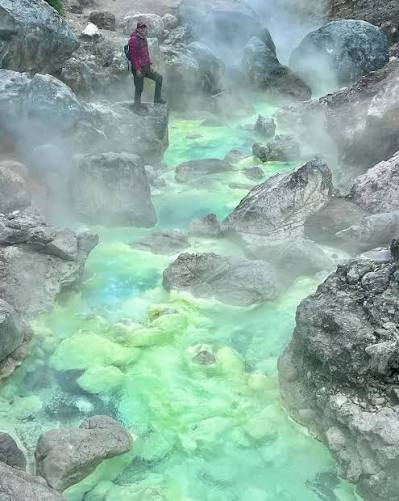
  <br>
  <em>Figura 1. Ecosistema de fuentes termales en el Parque Nacional Natural Los Nevados (PNNN), Colombia.</em>
</div>

---

### 🧬 Marcador Molecular de Alta Resolución: Gen *gyrB* (GO:0003918)

Para llevar a cabo la delineación taxonómica y la reconstrucción filogenética de alta resolución, no utilizaremos el gen ribosomal 16S ARNr convencional. En su lugar, utilizaremos el gen ***gyrB***, que codifica para la **subunidad B de la ADN girasa bacteriana** (topoisomerasa tipo II con actividad hidrolizante de ATP, clasificada bajo el término de la Gene Ontology **[GO:0003918](https://www.ebi.ac.uk/QuickGO/term/GO:0003918)**).

#### ¿Por qué el gen *gyrB* es superior al 16S ARNr en este clado?
* **Limitación del 16S ARNr:** Aunque el 16S ARNr es el estándar histórico en microbiología, sufre de una tasa de evolución extremadamente lenta y una alta conservación de secuencia. En bacterias del orden *Thermales* (géneros como *Thermus* y *Meiothermus*), especies distintas e incluso linajes con divergencias fisiológicas notables comparten con frecuencia más del **98.5% al 99.5% de identidad en su 16S ARNr**, resultando insuficiente para discriminar especies crípticas o definir límites taxonómicos a nivel de especie.
* **Ventajas de *gyrB*:** 
  1. **Copia única y universal:** Es un gen esencial de copia única en el cromosoma bacteriano, evitando los sesgos de paralogía y microheterogeneidad intragenómica que ocurren en el 16S ARNr (el cual puede presentar múltiples operones ribosomales divergentes en un mismo genoma).
  2. **Función crítica:** La ADN girasa introduce superenrollamiento negativo dependiente de ATP en la molécula de ADN bicatenario, función crucial para relajar el estrés torsional durante la replicación y transcripción cromosómica en ambientes hipertermófilos.
  3. **Mayor resolución discriminatoria:** Al codificar una proteína enzimática globular sujeta a presiones selectivas y degeneración de codones (sustituciones sinónimas en la tercera base), *gyrB* presenta una tasa de sustitución nucleotídica significativamente mayor que el 16S ARNr. Esto confiere una resolución filogenética de grano fino capaz de resolver con precisión ramas cortas, linajes hermanos y eventos de especiación reciente.


## 📂 Material Proporcionado en la Carpeta `./data/`

En la carpeta relativa `./data/` se encuentran los archivos necesarios para el desarrollo del parcial:

| Archivo | Tipo de Dato | Descripción |
|:---|:---|:---|
| `reads_R1.fastq` | FASTQ (Illumina PE) | Lecturas de secuenciación forward (R1) del aislado de fuentes termales del PNNN. |
| `reads_R2.fastq` | FASTQ (Illumina PE) | Lecturas de secuenciación reverse (R2) del aislado de fuentes termales del PNNN. |
| `coleccion_gyrB.fasta` | FASTA (Nucleótidos) | Colección ambiental y de referencia de secuencias homólogas del gen *gyrB* de especies termófilas y linajes emparentados. |

---

### 🛠️ Configuración de Rutas y Verificación del Directorio de Trabajo

Antes de iniciar la ejecución de las fases, verifiquen su directorio actual de trabajo y la existencia de los archivos de entrada.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## 1. Preprocesamiento y Control de Calidad

### Contexto Bioinformático
Las plataformas de secuenciación por síntesis (como Illumina) generan millones de lecturas cortas. Sin embargo, factores fisicoquímicos durante la polimerización secuencial pueden introducir acumulación de errores de secuenciación (disminución del puntaje de calidad Phred hacia el extremo 3') y contaminación con secuencias adaptadoras residuales de la preparación de librerías.

El puntaje Phred ($Q$) se define como:
$$Q = -10 \log_{10}(P)$$
donde $P$ es la probabilidad de que la base asignada sea errónea. Un puntaje $Q \ge 30$ representa una exactitud del 99.9% (probabilidad de error de 1 en 1,000).

### Herramientas Oficiales y Manuales de Referencia:
* **FastQC:** Software para análisis modular de calidad de lecturas de alto rendimiento.  
  📘 *Manual oficial:* [https://www.bioinformatics.babraham.ac.uk/projects/fastqc/Help/](https://www.bioinformatics.babraham.ac.uk/projects/fastqc/Help/)
* **MultiQC:** Plataforma para agregar y consolidar reportes bioinformáticos en un único informe interactivo.  
  📘 *Documentación oficial:* [https://multiqc.info/docs/](https://multiqc.info/docs/)
* **Trimmomatic:** Herramienta flexible para recorte de adaptadores y filtrado de lecturas FASTQ pareadas.  
  📘 *Manual oficial:* [http://www.usadellab.org/cms/?page=trimmomatic](http://www.usadellab.org/cms/?page=trimmomatic)

---

### 1.1 Control de Calidad Inicial (FastQC + MultiQC)
* **Instrucción:** Ejecuten `FastQC` sobre los archivos de lectura cruda `reads_R1.fastq` y `reads_R2.fastq` dentro de `./data/`.
* **Condición de cómputo:** Usar exactamente 2 hilos (`-t 2`).
* Consolidar los resultados generados empleando `MultiQC` para evaluar conjuntamente la calidad por base, contenido GC, longitud de lecturas y contenido de adaptadores.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 1.2 Depuración y Filtrado de Lecturas (Trimmomatic)
* **Instrucción:** A partir de los resultados observados en el reporte MultiQC inicial, apliquen `Trimmomatic` en modo `PE` (Paired-End) sobre las lecturas crudas.
* **Condición de cómputo:** Usar estrictamente 2 hilos (`-threads 2`).
* **Parámetros metodológicos requeridos:**
  1. `ILLUMINACLIP`: Remoción de secuencias adaptadoras Illumina.
  2. `SLIDINGWINDOW:4:20`: Ventana deslizante de 4 bases que recorta cuando el promedio Phred cae por debajo de 20.
  3. `MINLEN`: Descarte de lecturas cuya longitud final quede por debajo de un umbral aceptable (ej. 36 pb o 50 pb).
* Guardar las lecturas supervivientes pareadas en archivos limpios (ej. `clean_R1.fastq` y `clean_R2.fastq`).


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 1.3 Control de Calidad Post-Filtrado y Comparación
* **Instrucción:** Ejecuten nuevamente `FastQC` (`-t 2`) y `MultiQC` sobre las lecturas depuradas resultantes de Trimmomatic.
* Comprueben la eliminación efectiva de adaptadores y el incremento en los puntajes de calidad promedio por posición.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## 2. Ensamblaje *De Novo* y Evaluación Genómica

### Contexto Bioinformático
El ensamblaje *de novo* consiste en reconstruir el genoma a partir de las lecturas cortas sin disponer de un genoma de referencia para mapeo directo. Se fundamenta en algoritmos de **grafos de de Bruijn**, donde las lecturas se fragmentan en subsecuencias solapantes de longitud fija llamadas **$k$-meros**. 

Para organismos bacterianos puros secuenciados con buena cobertura, herramientas como **SPAdes** ensamblan las lecturas en fragmentos contiguos (**contigs**) y andamios (**scaffolds**). Posteriormente, es indispensable evaluar tanto la **contigüidad estructural** (usando **QUAST**) como la **completitud biológica** basada en ortólogos universales de copia única (usando **BUSCO**).

### Herramientas Oficiales y Manuales de Referencia:
* **SPAdes:** Ensamblador genómico de novo optimizado para lecturas cortas y genomas bacterianos aislados.  
  📘 *Manual oficial:* [https://cab.spbu.ru/software/spades/](https://cab.spbu.ru/software/spades/)
* **QUAST:** Herramienta para evaluación de calidad, contigüidad y métricas estructurales de ensamblajes genómicos.  
  📘 *Manual oficial:* [https://quast.sourceforge.net/docs/manual.html](https://quast.sourceforge.net/docs/manual.html)
* **BUSCO:** Evaluación cuantitativa de completitud biológica genómica mediante el análisis de genes ortólogos de copia única.  
  📘 *Manual oficial:* [https://busco.ezlab.org/busco_userguide.html](https://busco.ezlab.org/busco_userguide.html)

---

### 2.1 Ensamblaje *De Novo* con SPAdes
* **Instrucción:** Ensamblen el genoma bacteriano del aislado problema utilizando `SPAdes` a partir de las lecturas limpias pareadas (`clean_R1.fastq` y `clean_R2.fastq`).
* **Condición de cómputo y parámetros:**
  * Modo aislamiento: `spades.py --isolate` (o `--careful` si la versión lo sugiere para corrección de mismatches).
  * Estricto límite de 2 hilos: `-t 2`.
  * Restricción de memoria RAM moderada: `-m 3` o `-m 4` (en GB).
* El archivo resultante principal para los pasos posteriores será `contigs.fasta` (o `scaffolds.fasta`).


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 2.2 Evaluación de Contigüidad y Estructura con QUAST
* **Instrucción:** Evalúen el archivo `contigs.fasta` resultante del ensamblaje utilizando `QUAST`.
* **Condición de cómputo:** Usar exactamente 2 hilos (`-t 2`).
* **Métricas clave a reportar e interpretar:**
  * **N50:** Longitud del contig tal que la suma de contigs de igual o mayor tamaño abarca el 50% de la longitud total del ensamblaje.
  * **L50:** Número mínimo de contigs necesarios para alcanzar el 50% de la longitud acumulada del genoma.
  * **Longitud total acumulada del ensamblaje (pb).**
  * **Número total de contigs.**
  * **Porcentaje de GC.**


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 2.3 Evaluación de Completitud Génica con BUSCO
* **Instrucción:** Evalúen la integridad biológica del ensamblaje ejecutando `BUSCO` sobre `contigs.fasta`.
* **Condición de cómputo:** Usar estrictamente 2 hilos (`--cpu 2`).
* **Parámetros:**
  * Modo de análisis: `-m genome`.
  * Base de datos de linaje: linaje bacteriano universal (`-l bacteria_odb10`).
* Analizar las categorías: Complete (Single-copy y Duplicated), Fragmented y Missing.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## 3. Anotación Estructural, Funcional y Extracción del Marcador *gyrB*

### Contexto Bioinformático
Una vez ensamblado el genoma, el siguiente paso es la **anotación estructural y funcional**:
1. **Anotación Estructural:** Identificación y delimitación de elementos génicos dentro de las secuencias ensambladas (Secuencias Codificantes de Proteínas o **CDS**, ARN de transferencia **tRNA**, y ARN ribosomal **rRNA**). **Prokka** integra múltiples herramientas de predicción (como Prodigal, Aragorn y RNAmmer) en un flujo rápido y automatizado.
2. **Anotación Funcional:** Asignación de significados biológicos, funciones moleculares, rutas metabólicas y dominios a los CDS predichos. **eggNOG-mapper** (`emapper.py`) mapea las secuencias proteicas contra la base de datos de ortología evolutiva eggNOG, proporcionando anotaciones robustas de Gene Ontology (**GO**), Enzyme Commission (**EC**), dominios **Pfam** y rutas **KEGG**.

Finalmente, utilizando el término ontológico de la actividad de ADN girasa (**GO:0003918**), localizaremos el gen ***gyrB*** en el genoma anotado y extraeremos su secuencia nucleotídica completa mediante **SeqKit** para su posterior análisis comparativo y filogenético.

### Herramientas Oficiales y Manuales de Referencia:
* **Prokka:** Software integral para la anotación estructural rápida de genomas procariotas.  
  📘 *Manual oficial (Debian manpage):* [https://manpages.debian.org/testing/prokka/prokka.1.en.html](https://manpages.debian.org/testing/prokka/prokka.1.en.html)
* **eggNOG-mapper:** Herramienta para anotación funcional basada en ortología rápida y precisa.  
  📘 *Documentación oficial:* [http://eggnog-mapper.embl.de/documentation.html](http://eggnog-mapper.embl.de/documentation.html)
* **SeqKit:** Suite de herramientas de línea de comandos ultrarrápida para manipulación y extracción de secuencias FASTA/Q.  
  📘 *Documentación oficial:* [https://bioinf.shenwei.me/seqkit/](https://bioinf.shenwei.me/seqkit/)

---

### 3.1 Anotación Estructural con Prokka
* **Instrucción:** Ejecuten `Prokka` sobre el archivo de ensamblaje `contigs.fasta`.
* **Condición de cómputo:** Usar exactamente 2 hilos (`--cpus 2`).
* Verifiquen los archivos de salida generados, especialmente:
  * `*.faa`: Secuencias de aminoácidos de todos los CDS traducidos.
  * `*.ffn`: Secuencias de nucleótidos de las regiones codificantes predichas.
  * `*.tsv` / `*.gff`: Tablas con coordenadas genómicas, locus tags y anotaciones preliminares.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 3.2 Anotación Funcional con eggNOG-mapper
* **Instrucción:** Ejecuten `emapper.py` tomando como entrada el archivo de proteínas predichas (`*.faa`) generado por Prokka.
* **Condición de cómputo:** Usar estrictamente 2 hilos (`--cpu 2`).
* **Parámetros de aceleración:** Utilicen `--dmnd_algo ctg --sensmode default --dmnd_iterate no` para optimizar y acelerar sustancialmente la búsqueda en Diamond.
* El comando generará el archivo de anotaciones funcionales `*.emapper.annotations` con asignaciones de términos GO, nombres preferidos de genes y grupos de ortología.


In [ ]:
# 3.2 Anotación funcional con eggNOG-mapper (--cpu 2 --dmnd_algo ctg --sensmode default --dmnd_iterate no)
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 3.3 Identificación y Localización del Gen *gyrB* (GO:0003918)
* **Instrucción:** Consulten la tabla de anotaciones funcionales (`*.emapper.annotations`) o la tabla de Prokka (`*.tsv`) para encontrar el gen ***gyrB***.
* **Criterio de búsqueda:**
  * Búsqueda por término ontológico de Gene Ontology: **`GO:0003918`** (DNA topoisomerase type II (ATP-hydrolyzing) activity).
  * Confirmación por nombre preferido del gen (`gyrB`) o descripción funcional ("DNA gyrase subunit B").
* **Objetivo:** Recuperar el identificador exacto de **`locus_tag`** asignado por Prokka a este gen (ej. `PROKKA_XXXXX`).


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 3.4 Extracción de la Secuencia Nucleotídica de *gyrB* con SeqKit
* **Instrucción:** Utilicen `seqkit grep` para extraer del archivo de nucleótidos `*.ffn` de Prokka la secuencia correspondiente al `locus_tag` identificado de *gyrB*.
* Guardar la secuencia extraída en un nuevo archivo FASTA (ej. `gyrB_aislado.fasta`).
* Verificar que la secuencia extraída posea la longitud adecuada (típicamente entre 1,800 y 2,100 pb para la subunidad B de la ADN girasa) y comience con un codón de inicio válido.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## 4. Genómica Comparativa y Detección de Organismos Fuera de Distribución (OFDs) con PCoA

### Contexto Bioinformático
En estudios de metagenómica ambiental y bioprospección geotermal, las colecciones de secuencias pueden contener contaminantes, quimeras, artefactos de secuenciación o especies taxonómicamente lejanas que no pertenecen al clado biológico de interés. A estos elementos discordantes los denominamos **OFDs** (*Organismos Fuera de la Distribución* / Outliers).

Si se construye una filogenia incluyendo OFDs distantes, se producen fenómenos de distorsión evolutiva como la **atracción de ramas largas** (*Long Branch Attraction* - LBA), arruinando la topología y las relaciones entre especies hermanas.

Para detectar y eliminar OFDs de forma matemáticamente rigurosa:
1. Integramos la secuencia de *gyrB* extraída de nuestro aislado a la colección de referencia (`coleccion_gyrB.fasta`).
2. Realizamos un alineamiento múltiple de secuencias (**MSA**) masivo con **MUSCLE**.
3. Calculamos una **matriz de distancias genéticas por pares** (distancia de Hamming o p-distancia normalizada).
4. Proyectamos las distancias en un espacio euclidiano de baja dimensión mediante **Análisis de Coordenadas Principales (PCoA / MDS métrico)** usando **scikit-learn** y **SciPy**.
5. Graficamos la dispersión bidimensional (**PC1 vs PC2**) con **Matplotlib**, identificamos visual y numéricamente los OFDs y procedemos a depurarlos.

### Herramientas Oficiales y Manuales de Referencia:
* **MUSCLE:** Algoritmo rápido y escalable para alineamiento múltiple de secuencias de nucleótidos y aminoácidos.  
  📘 *Manual oficial:* [https://drive5.com/muscle/manual/](https://drive5.com/muscle/manual/)
* **SciPy Spatial Distance:** Módulo para cálculo de matrices de distancia p-norm, Hamming, Jaccard y euclidiana.  
  📘 *Documentación oficial:* [https://docs.scipy.org/doc/scipy/reference/spatial.distance.html](https://docs.scipy.org/doc/scipy/reference/spatial.distance.html)
* **scikit-learn MDS / PCoA:** Implementación de Escalamiento Multidimensional (MDS) para análisis de coordenadas principales a partir de matrices de disimilitud precalculadas.  
  📘 *Documentación oficial:* [https://scikit-learn.org/stable/modules/generated/sklearn.manifold.MDS.html](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.MDS.html)
* **Matplotlib Pyplot Scatter:** Función para renderizado y visualización de gráficos de dispersión 2D/3D con anotaciones y mapas de color.  
  📘 *Documentación oficial:* [https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html)

---

### 4.1 Consolidación del Dataset de Secuencias
* **Instrucción:** Agreguen la secuencia de *gyrB* extraída de su aislado (del Punto 3.4) al archivo `coleccion_gyrB.fasta` ubicado en `./data/`.
* Renombren el encabezado FASTA de su aislado para distinguirlo claramente (ej. `>Thermus_thermophilus_PNNN_aislado`).
* Guardar el archivo consolidado (ej. `coleccion_con_aislado.fasta`).


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 4.2 Alineamiento Múltiple de Secuencias con MUSCLE
* **Instrucción:** Alineen el archivo consolidado de secuencias con `MUSCLE`.
* **Condición de cómputo:** Limitar la ejecución a 2 hilos si su versión de MUSCLE soporta paralelismo (`-threads 2`), o ejecutar el algoritmo estándar respetando los recursos compartidos.
* Guardar el alineamiento resultante en formato FASTA (ej. `alineamiento_gyrB_completo.fasta`).


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 4.3 Cálculo de la Matriz de Distancias Genéticas (Hamming / p-distance)
* **Instrucción:** En Python, carguen el alineamiento múltiple (utilizando `Bio.AlignIO` o `Bio.SeqIO`).
* Conviertan las secuencias alineadas en una matriz numérica o calculen la distancia de Hamming normalizada (proporción de diferencias por sitio de alineamiento, omitiendo gaps o tratándolos homogéneamente) mediante funciones de `scipy.spatial.distance` o cálculo directo en NumPy.
* Obtener una matriz cuadrada de disimilitud de dimensión $N \times N$.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 4.4 Análisis de Coordenadas Principales (PCoA / MDS) y Detección de OFDs
* **Instrucción:** Apliquen `sklearn.manifold.MDS` sobre la matriz de distancias precalculada (`dissimilarity='precomputed'`, `n_components=2`, `random_state=42`).
* Generen un gráfico de dispersión bidimensional (**PC1 vs PC2**) utilizando `matplotlib.pyplot.scatter`.
* Etiqueten los puntos con los nombres de las especies o taxones.
* Resalten la posición de su aislado (*Thermus thermophilus* PNNN) y señalen los **OFDs** (taxones anómalos o atípicos que se ubican alejados del grupo principal).


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 4.5 Depuración y Filtrado de los OFDs
* **Instrucción:** A partir del gráfico PCoA, identifiquen la lista de nombres de taxones catalogados como OFDs.
* Filtren el dataset de secuencias removiendo los OFDs, conservando únicamente el conjunto coherente y monofilético que contiene a su aislado y las especies termófilas afines.
* Guardar la colección depurada en un nuevo archivo (ej. `coleccion_gyrB_sin_OFDs.fasta`).


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## 5. Señales Evolutivas y Reconstrucción Filogenética

### Contexto Bioinformático
La inferencia filogenética molecular busca reconstruir las relaciones evolutivas y la historia de divergencia de los organismos a partir de secuencias homólogas. 

En métodos basados en matrices de distancia:
1. **Modelo de Jukes-Cantor (JC69):** Corrige la saturación mutacional asumiendo tasas de sustitución iguales entre todos los nucleótidos ($\alpha$) y frecuencias de bases idénticas ($1/4$). La distancia evolutiva corregida se calcula como:
   $$d = -\frac{3}{4} \ln \left( 1 - \frac{4}{3} p \right)$$
   donde $p$ es la fracción de sitios observados con diferencias.
2. **Algoritmos de Agrupamiento Jerárquico:**
   * **Neighbor-Joining (NJ):** Método de agrupamiento no enraizado basado en el principio de evolución mínima que no asume un reloj molecular estricto, manejando eficientemente tasas variables de evolución en diferentes linajes.

Utilizaremos el módulo **BioPython Phylo** para calcular la matriz de distancias bajo el modelo de sustitución nucleotídica, construir el árbol filogenético con `DistanceTreeConstructor` y visualizar el cladograma con soporte gráfico en Matplotlib.

### Herramientas Oficiales y Manuales de Referencia:
* **BioPython Phylo Wiki:** Guía completa del submódulo `Bio.Phylo` para análisis y manipulación de árboles filogenéticos en Python.  
  📘 *Documentación oficial:* [https://biopython.org/wiki/Phylo](https://biopython.org/wiki/Phylo)
* **Bio.Phylo.TreeConstruction API:** Referencia oficial de clases y métodos de construcción de árboles (`DistanceCalculator`, `DistanceTreeConstructor`).  
  📘 *Documentación oficial:* [https://biopython.org/docs/latest/api/Bio.Phylo.TreeConstruction.html](https://biopython.org/docs/latest/api/Bio.Phylo.TreeConstruction.html)
* **Tutorial Oficial de BioPython (Capítulo Phylo):** Guía práctica paso a paso para análisis filogenético.  
  📘 *Tutorial oficial:* [https://biopython.org/DIST/docs/tutorial/Tutorial.html#sec379](https://biopython.org/DIST/docs/tutorial/Tutorial.html#sec379)

---

### 5.1 Realineamiento de la Colección Depurada sin OFDs
* **Instrucción:** Alineen con `MUSCLE` el archivo limpio que contiene únicamente las secuencias depuradas sin OFDs (`coleccion_gyrB_sin_OFDs.fasta`).
* **Condición de cómputo:** Usar máximo 2 hilos (`-threads 2`).
* Guardar el alineamiento final refinado (ej. `alineamiento_gyrB_depurado.fasta`).


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 5.2 Construcción del Árbol Filogenético en BioPython
* **Instrucción:** Utilicen las clases `DistanceCalculator` y `DistanceTreeConstructor` del paquete `Bio.Phylo.TreeConstruction`.
* **Metodología:**
  1. Cargar el alineamiento depurado con `Bio.AlignIO.read("alineamiento_gyrB_depurado.fasta", "fasta")`.
  2. Calcular la matriz de distancias empleando el modelo nucleotídico de Jukes-Cantor o identidad (`DistanceCalculator('jukescantor')`).
  3. Inferir el árbol filogenético aplicando el algoritmo **Neighbor-Joining (NJ)** (`nj()`) mediante `DistanceTreeConstructor`.
  4. Guardar el árbol en formato Newick o XML (ej. `arbol_filogenetico_gyrB.nwk`).


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 5.3 Visualización Gráfica y Marcación de Taxones Hermanos
* **Instrucción:** Rendericen el árbol filogenético utilizando `Bio.Phylo.draw` junto con `matplotlib.pyplot`.
* **Requerimientos visuales:**
  * Configurar tamaño de figura y legibilidad de etiquetas de los taxones.
  * Resaltar visualmente (mediante color de nodo, anotación o caja de texto) la ubicación de su aislado (*Thermus thermophilus* PNNN).
  * Identificar e indicar de forma explícita los **taxones hermanos (*sister taxa*)** inmediatos que forman clado monofilético con su aislado.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)
